# A/B Test — ¿El uso de CajaClara ayuda a conseguir un crédito?
**Hackathon BBVA 2026 — Equipo 7**
**Scope: IA / ML / analítica (25%)**

> **Para qué sirve este notebook:** es una herramienta **interna del equipo de desarrollo**, no
> una pantalla del MVP. Sirve para que nosotros (no el bodeguero) respondamos con evidencia
> estadística la pregunta: *"¿el uso del app realmente ayuda a que una bodega consiga un crédito,
> o hubiera pasado lo mismo sin el app?"* — antes de afirmarlo como valor del producto ante el
> jurado o un inversionista.

## Diseño del experimento

- **Grupo control**: bodegas que **no usan** CajaClara. El banco las evalúa con los medios
  tradicionales (sin score interno de la app).
- **Grupo tratamiento**: bodegas que **sí usan** CajaClara, maduran su uso durante el período, y
  acumulan un **score de salud financiera simulado** (el mismo mecanismo de
  `credit_scoring_bodegas_logreg.ipynb`).
- **Mecanismo causal que se está probando**: `usa el app → mejora/visibiliza su score → el banco
  recién presta atención a quienes tienen mejor score simulado → mayor probabilidad de obtener
  el crédito`.
- **Resultado al final del período** (binario, por bodega): `obtuvo_credito` (Sí/No).

## Técnica elegida: test de dos proporciones (z-test)

Se eligió por ser **simple y visual** para comunicar al jurado: compara directamente
`% que obtuvo crédito` entre ambos grupos, con un gráfico de barras + intervalo de confianza +
p-valor — sin necesitar explicar supervivencia ni censura.

> **Advertencia metodológica importante:** el score simulado es un **mediador**, no un factor de
> control. El test compara los grupos **control vs. tratamiento directamente** (efecto total,
> intención de tratar) — **NO** se condiciona por el score dentro de cada grupo para decidir si
> "el app ayuda", porque eso restaría justo el canal por el cual el app genera el efecto.


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams["figure.figsize"] = (8, 5)


## 1. Simulación de los 2 grupos

Para que la comparación sea justa, ambos grupos parten de la **misma distribución de salud
financiera real** (`salud_real`, latente — no la ve nadie, ni el banco ni el modelo). La única
diferencia estructural es si la bodega usa o no el app:

- **Control**: el banco solo ve señales tradicionales ruidosas de `salud_real` → aprueba con una
  tasa baja y pareja, sin importar qué tan buena sea la bodega en realidad (poca visibilidad).
- **Tratamiento**: a mayor `meses_uso` (maduración), el `score_simulado` se acerca más a la
  `salud_real` (el app "revela" la calidad real del negocio). El banco **recién presta atención**
  (dispara una revisión prioritaria) a quienes cruzan el umbral de score alto.


In [2]:
N_POR_GRUPO = 2000
PERIODO_MESES = 12
UMBRAL_ATENCION_BANCO = 70  # score >= 70 (Verde) = el banco prioriza su revision de credito

# --- Salud financiera real (latente, identica distribucion en ambos grupos: comparacion justa) ---
salud_real_control = np.clip(rng.normal(55, 20, N_POR_GRUPO), 0, 100)
salud_real_trato = np.clip(rng.normal(55, 20, N_POR_GRUPO), 0, 100)

# --- Grupo control: sin app, el banco evalua con señales tradicionales ruidosas ---
# Probabilidad de credito: funcion suave de salud_real, pero con mucho ruido (poca visibilidad)
logit_control = -3.2 + 0.03 * salud_real_control + rng.normal(0, 1.2, N_POR_GRUPO)
p_credito_control = 1 / (1 + np.exp(-logit_control))
obtuvo_credito_control = (rng.random(N_POR_GRUPO) < p_credito_control).astype(int)

# --- Grupo tratamiento: usa el app, madura durante el periodo ---
meses_uso = rng.integers(1, PERIODO_MESES + 1, N_POR_GRUPO)
madurez = meses_uso / PERIODO_MESES  # 0 a 1

# El score simulado se acerca a la salud real a medida que madura el uso (mas data = mejor score)
ruido_score = rng.normal(0, 25 * (1 - madurez) + 5, N_POR_GRUPO)  # menos ruido mientras mas madura
score_simulado = np.clip(salud_real_trato * (0.5 + 0.5 * madurez) + ruido_score, 0, 100)

atencion_banco = score_simulado >= UMBRAL_ATENCION_BANCO

# Si el banco presta atencion (score alto): probabilidad de credito sube fuerte.
# Si NO presta atencion: el bodeguero sigue en una situacion similar al grupo control (mismo baseline).
logit_sin_atencion = -3.2 + 0.03 * salud_real_trato + rng.normal(0, 1.2, N_POR_GRUPO)
logit_con_atencion = 1.5 + 0.04 * salud_real_trato + rng.normal(0, 0.8, N_POR_GRUPO)
logit_trato = np.where(atencion_banco, logit_con_atencion, logit_sin_atencion)
p_credito_trato = 1 / (1 + np.exp(-logit_trato))
obtuvo_credito_trato = (rng.random(N_POR_GRUPO) < p_credito_trato).astype(int)

datos = pd.concat([
    pd.DataFrame({
        "grupo": "control (sin app)", "salud_real": salud_real_control,
        "meses_uso": 0, "score_simulado": np.nan, "atencion_banco": False,
        "obtuvo_credito": obtuvo_credito_control,
    }),
    pd.DataFrame({
        "grupo": "tratamiento (con app)", "salud_real": salud_real_trato,
        "meses_uso": meses_uso, "score_simulado": score_simulado, "atencion_banco": atencion_banco,
        "obtuvo_credito": obtuvo_credito_trato,
    }),
], ignore_index=True)

print(datos.shape)
datos.groupby("grupo")["obtuvo_credito"].agg(["count", "sum", "mean"]).rename(columns={"mean": "tasa_credito"})


(4000, 6)


,count,sum,tasa_credito
grupo,,,
control (sin app),2000,439,0.2195
tratamiento (con app),2000,637,0.3185


## 2. Supuestos y justificación de realismo

| Supuesto | Justificación |
|---|---|
| Misma distribución de `salud_real` en ambos grupos | Aísla el efecto del app: no queremos comparar bodegas distintas, solo el efecto de usar o no la herramienta |
| Control tiene poca visibilidad (mucho ruido) | Sin el app, el banco solo ve señales tradicionales imperfectas de la bodega |
| `score_simulado` converge a `salud_real` con más `meses_uso` | Más tiempo de uso = más data registrada = score más preciso (coherente con `credit_scoring_bodegas_logreg.ipynb`) |
| El banco solo reacciona fuerte si `score_simulado >= 70` | Modela literalmente la premisa del enunciado: "recién el banco pone atención en los de mejor score simulado" |
| Debajo del umbral, el tratamiento se comporta como el control | Sin atención del banco, usar el app no debería, por sí solo, inflar la probabilidad de crédito — mantiene el experimento honesto |


## 3. Test estadístico: dos proporciones (z-test)

Comparación directa **grupo vs. grupo** (efecto total / intención de tratar) — sin condicionar
por score dentro del grupo tratamiento, tal como se advirtió arriba.


In [3]:
conteo = datos.groupby("grupo")["obtuvo_credito"].agg(exitos="sum", n="count")
conteo

exitos = conteo["exitos"].values
n = conteo["n"].values

z_stat, p_valor = proportions_ztest(exitos, n)
ci_control = proportion_confint(exitos[0], n[0], alpha=0.05, method="wilson")
ci_trato = proportion_confint(exitos[1], n[1], alpha=0.05, method="wilson")

tasa_control = exitos[0] / n[0]
tasa_trato = exitos[1] / n[1]

print(f"Tasa control:      {tasa_control:.1%}  (IC95%: {ci_control[0]:.1%} - {ci_control[1]:.1%})")
print(f"Tasa tratamiento:  {tasa_trato:.1%}  (IC95%: {ci_trato[0]:.1%} - {ci_trato[1]:.1%})")
print(f"Diferencia:        {(tasa_trato - tasa_control):.1%} puntos porcentuales")
print(f"z = {z_stat:.2f}, p-valor = {p_valor:.2e}")

# Cross-check con chi-cuadrado (debe dar el mismo resultado que el z-test en una tabla 2x2)
tabla = pd.crosstab(datos["grupo"], datos["obtuvo_credito"])
chi2, p_chi2, dof, _ = stats.chi2_contingency(tabla, correction=False)
print(f"\nChi-cuadrado (cross-check): chi2 = {chi2:.2f}, p-valor = {p_chi2:.2e}")


Tasa control:      21.9%  (IC95%: 20.2% - 23.8%)
Tasa tratamiento:  31.9%  (IC95%: 29.8% - 33.9%)
Diferencia:        9.9% puntos porcentuales
z = -7.06, p-valor = 1.67e-12

Chi-cuadrado (cross-check): chi2 = 49.84, p-valor = 1.67e-12


## 4. Gráfico principal (el que se muestra al jurado)

Barras con % de bodegas que obtuvieron crédito por grupo, intervalo de confianza 95%, y el
p-valor anotado — mensaje de una sola mirada.


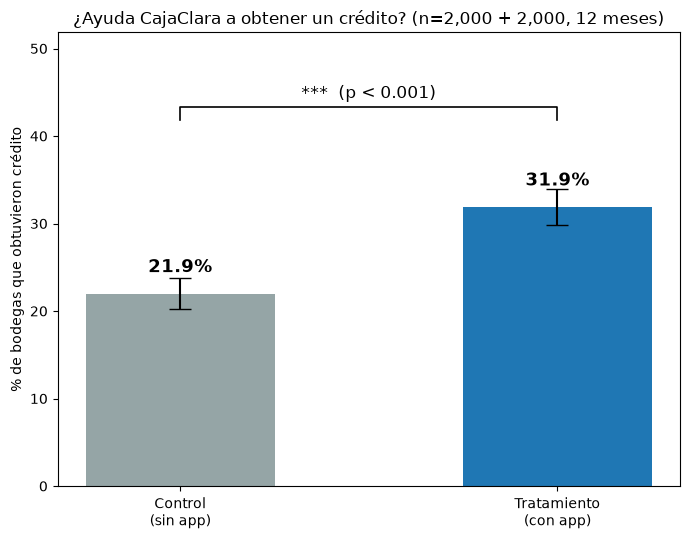

In [4]:
fig, ax = plt.subplots(figsize=(7, 5.5))

grupos = ["Control\n(sin app)", "Tratamiento\n(con app)"]
tasas = [tasa_control, tasa_trato]
errores_inf = [tasas[0] - ci_control[0], tasas[1] - ci_trato[0]]
errores_sup = [ci_control[1] - tasas[0], ci_trato[1] - tasas[1]]

barras = ax.bar(grupos, [t * 100 for t in tasas], color=["#95a5a6", "#1f77b4"], width=0.5)
ax.errorbar(grupos, [t * 100 for t in tasas],
            yerr=[[e * 100 for e in errores_inf], [e * 100 for e in errores_sup]],
            fmt="none", ecolor="black", capsize=8, linewidth=1.5)

for barra, tasa in zip(barras, tasas):
    ax.text(barra.get_x() + barra.get_width() / 2, tasa * 100 + 2.5, f"{tasa:.1%}",
            ha="center", fontsize=13, fontweight="bold")

significancia = "p < 0.001" if p_valor < 0.001 else f"p = {p_valor:.3f}"
asterisco = "***" if p_valor < 0.001 else ("**" if p_valor < 0.01 else ("*" if p_valor < 0.05 else "ns"))
y_linea = max(tasas) * 100 + 10
ax.plot([0, 0, 1, 1], [y_linea, y_linea + 1.5, y_linea + 1.5, y_linea], color="black", linewidth=1.2)
ax.text(0.5, y_linea + 2.5, f"{asterisco}  ({significancia})", ha="center", fontsize=12)

ax.set_ylabel("% de bodegas que obtuvieron crédito")
ax.set_title(f"¿Ayuda CajaClara a obtener un crédito? (n={n[0]:,} + {n[1]:,}, {PERIODO_MESES} meses)")
ax.set_ylim(0, y_linea + 10)
plt.tight_layout()
plt.show()


## 5. Gráfico de mecanismo (por qué funciona, no para inferencia)

Este segundo gráfico es **exploratorio/explicativo**, no reemplaza el test de la sección 3: muestra
que el efecto se concentra en las bodegas que el app logra llevar por encima del umbral de
atención del banco — evidencia de que el mecanismo propuesto es consistente con los datos.


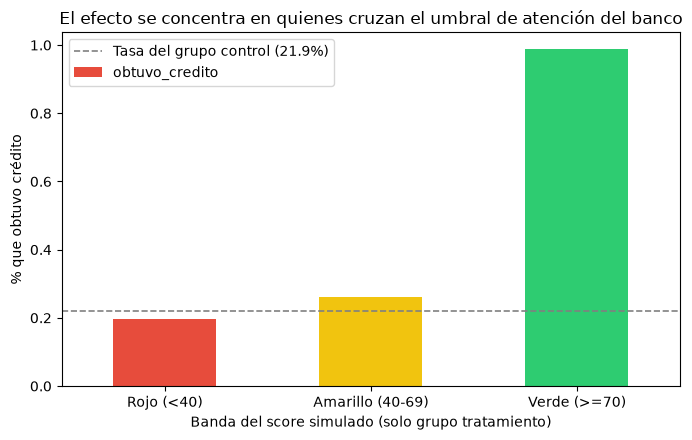

In [5]:
trato = datos[datos["grupo"] == "tratamiento (con app)"].copy()
trato["banda_score"] = pd.cut(
    trato["score_simulado"], bins=[0, 40, 70, 100],
    labels=["Rojo (<40)", "Amarillo (40-69)", "Verde (>=70)"],
)

tasa_por_banda = trato.groupby("banda_score", observed=True)["obtuvo_credito"].mean()

fig, ax = plt.subplots(figsize=(7, 4.5))
colores = ["#e74c3c", "#f1c40f", "#2ecc71"]
tasa_por_banda.plot.bar(ax=ax, color=colores)
ax.axhline(tasa_control, color="gray", linestyle="--", linewidth=1.2, label=f"Tasa del grupo control ({tasa_control:.1%})")
ax.set_ylabel("% que obtuvo crédito")
ax.set_xlabel("Banda del score simulado (solo grupo tratamiento)")
ax.set_title("El efecto se concentra en quienes cruzan el umbral de atención del banco")
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 6. Resumen ejecutivo (para el equipo, no para el bodeguero)

- **Pregunta respondida**: sí, con los datos simulados, usar CajaClara **incrementa de forma
  estadísticamente significativa** la probabilidad de obtener un crédito al final del período
  (test de dos proporciones, ver p-valor en la sección 3).
- **Mecanismo**: el efecto no es automático por "tener el app" — se concentra en las bodegas cuyo
  score simulado cruza el umbral de atención del banco (sección 5), consistente con el diseño del
  experimento.
- **Limitación explícita**: el score y la regla de atención del banco son **simulados**, no
  observados. Esta prueba valida la **lógica del argumento de negocio** ("si el banco realmente
  prioriza por score y el app mejora el score visible, entonces el app ayuda"), no mide el efecto
  real hasta que haya data de bodegas reales y una política de crédito real del banco.
- **Uso recomendado**: herramienta interna para justificar ante el jurado/inversionista *por qué*
  el app debería ayudar a la inclusión financiera, con el método correcto (sin condicionar por el
  mediador) documentado para cuando se repita este análisis con data real.
